In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import random
from torch import nn

In [2]:
batch_size = 1

transform = transforms.Compose([transforms.ToTensor(),])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                      download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)

  0%|          | 0/170498071 [00:00<?, ?it/s]

Extracting ./data/cifar-10-python.tar.gz to ./data
Files already downloaded and verified


In [3]:
subset_1 = random.sample(range(1, 25000), 200)
subset_1 = torch.utils.data.Subset(trainset, subset_1)
subset_2 = random.sample(range(25000, 50000), 200)
subset_2 = torch.utils.data.Subset(trainset, subset_2)
subloader_1 = torch.utils.data.DataLoader(subset_1, batch_size=batch_size,
                                         shuffle=False, num_workers=2)
subloader_2 = torch.utils.data.DataLoader(subset_2, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

In [4]:
type(subset_1)

torch.utils.data.dataset.Subset

In [5]:
type(subloader_1)

torch.utils.data.dataloader.DataLoader

In [ ]:
subset_1 = random.sample(range(1, 5000), 500)
subset_1 = torch.utils.data.Subset(testset, subset_1)
testloader_1 = torch.utils.data.DataLoader(subset_1, batch_size=batch_size,
                                         shuffle=False, num_workers=2)
subset_2 = random.sample(range(5000, 10000), 500)
subset_2 = torch.utils.data.Subset(testset, subset_2)
testloader_2 = torch.utils.data.DataLoader(subset_2, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

In [ ]:
class TwoOutputsAE(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = torch.nn.Sequential(
            nn.Conv2d(3, 12, 4, stride=2, padding=1),            
            nn.ReLU(),
            nn.Conv2d(12, 24, 4, stride=2, padding=1),         
            nn.ReLU(),
            nn.Conv2d(24, 48, 4, stride=2, padding=1),           
            nn.ReLU(),
        )
        self.decoder_1 = torch.nn.Sequential(
            nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1),  
            nn.ReLU(),
            nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1),  
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1), 
            nn.Sigmoid(),
        )
        self.decoder_2 = torch.nn.Sequential(
            nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded_1 = self.decoder_1(encoded)
        decoded_2 = self.decoder_2(encoded)
        return decoded_1, decoded_2


In [ ]:
def im_convert(tensor):  
    image = tensor.cpu().clone().detach().numpy() 
    image = image.transpose(1, 2, 0)
    image = image * np.array((0.5, 0.5, 0.5)) + np.array((0.5, 0.5, 0.5))
    image = image.clip(0, 1)
    return image

In [ ]:
def create_input(tar1, tar2):
    inputs = [((tar1.cpu()[0].numpy()+tar2.cpu()[0].numpy())/2).tolist()]
    return torch.FloatTensor(inputs)

In [ ]:
def create_model():
    autoencoder = TwoOutputsAE()
    if torch.cuda.is_available():
        autoencoder = autoencoder.cuda()
        print("Model moved to GPU in order to speed up training.")
    return autoencoder

In [ ]:
def imshow(img):
    npimg = img.cpu().numpy()
    plt.axis('off')
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

In [ ]:
image_1, label_1 = subset_1[0]
image_2, label_2 = subset_2[0]

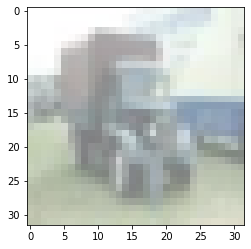

In [ ]:
plt.imshow(im_convert(image_1))

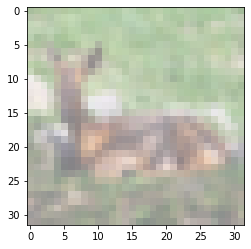

In [ ]:
plt.imshow(im_convert(image_2))

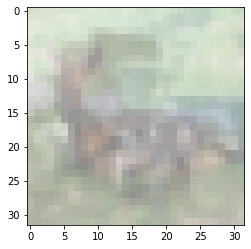

In [ ]:
plt.imshow(im_convert((image_1 + image_2)/2))

In [ ]:
SEED = 87
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

In [ ]:
model = create_model()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters())

Model moved to GPU in order to speed up training.


In [ ]:
epochs = 10
losses = []
for epoch in range(epochs):
    running_loss = 0.0
    print(f"Running epoch {epoch+1} out of {epochs}")
    
    for tar1 in subloader_1:
        tar1 = tar1[0]
        tar1 = tar1.cuda()
        for tar2 in subloader_2:
            tar2 = tar2[0] 
            inp = create_input(tar1, tar2)
            inp = inp.cuda()
            tar2 = tar2.cuda()
            out1, out2 = model(inp)
            out1 = out1.cuda()
            out2 = out2.cuda()
            loss_1 = criterion(out1, tar1)
            loss_2 = criterion(out2, tar2)
            loss = loss_1 + loss_2
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.data
    losses.append(running_loss/40000)
    print(f"loss: {losses[-1]}")

print('Finished Training')

Running epoch 1 out of 10

loss: 0.03515692800283432

Running epoch 2 out of 10

loss: 0.03513031452894211

Running epoch 3 out of 10

loss: 0.034807927906513214

Running epoch 4 out of 10

loss: 0.03449535742402077

Running epoch 5 out of 10

loss: 0.034178417176008224

Running epoch 6 out of 10

loss: 0.033543627709150314

Running epoch 7 out of 10

loss: 0.0328805036842823

Running epoch 8 out of 10

loss: 0.032323841005563736

Running epoch 9 out of 10

loss: 0.031933240592479706

Running epoch 10 out of 10

loss: 0.031349703669548035

Finished Training


We use MSELoss as loss function and Adam as optimizer. During trainig the two losses of outputs must be added together and then loss.backward() is used.  
As inputs we calculate the average of 200 * 200 images(40000 inputs are created).

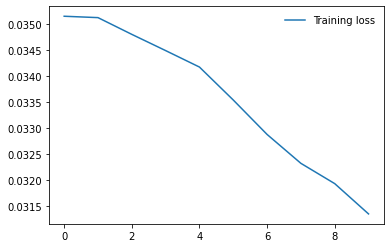

In [ ]:
ls = []
for loss in losses:
    ls.append(float(loss.cpu()))
          
plt.plot(ls, label='Training loss')
plt.legend(frameon=False)
plt.show()

Real images:


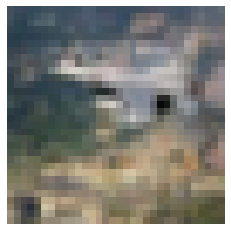

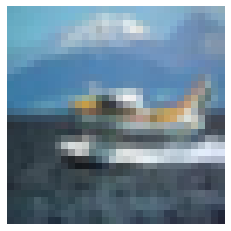

Average image:


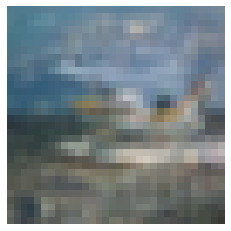

Predicted images:


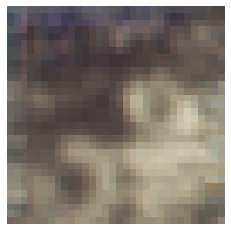

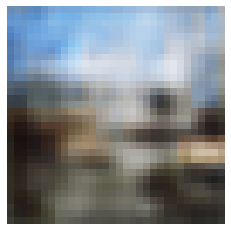



***********



Real images:


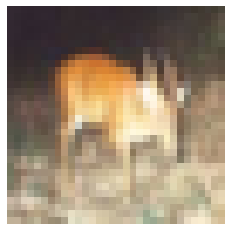

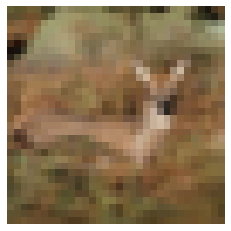

Average image:


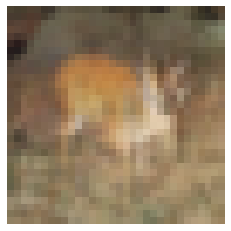

Predicted images:


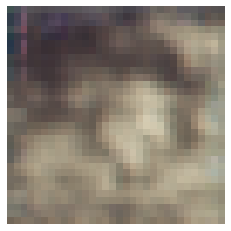

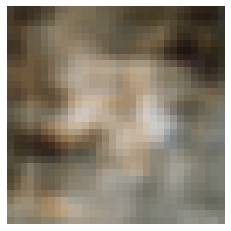



***********



Number of images Tested= 1000



Total Loss= tensor(0.1285, device='cuda:0')


In [ ]:
total_loss = 0.0
i = 0
for tar1, tar2 in zip(testloader_1, testloader_2):
    tar1 = tar1[0]
    tar2 = tar2[0]
    tar1 = tar1.cuda()
    tar2 = tar2.cuda()
    inp = create_input(tar1, tar2)
    inp = inp.cuda()
    out1, out2 = model(inp)
    out1 = out1.cuda()
    out2 = out2.cuda()
    loss_1 = criterion(out1, tar1)
    loss_2 = criterion(out2, tar2)
    loss = loss_1 + loss_2
    total_loss += loss.data
    if i % 250 == 249:
        print("Real images:")
        imshow(torchvision.utils.make_grid(tar1.data))
        imshow(torchvision.utils.make_grid(tar2.data))
        print("Average image:")
        imshow(torchvision.utils.make_grid(inp.data))
        print("Predicted images:")
        imshow(torchvision.utils.make_grid(out1.data))
        imshow(torchvision.utils.make_grid(out2.data))
        print("\n***********\n")
    i+=1
        
print("Number of images Tested=", 1000)
print("\nTotal Loss=",(total_loss/500))